# Do commodity price moves lead industry returns?

Course project for APM_5FI15_AE "ML for Trading" (ENSAE Paris, M2 SFA), Selim-Antoine Lali and Quentin Borne, October 2026.

*Work in progress: for now the notebook only loads the data (Section 2).*

**Hypothesis.** Last month's moves in commodity prices (oil, gas, coal, metals, grains) predict next month's returns of the Ken French industry portfolios. The sign should depend on whether an industry produces the commodity (Oil, Coal, Mines, Gold, Agric) or uses it as an input (Trans, Chems, Autos, Util, Steel). The mechanism we have in mind is a slow diffusion of information from commodity markets to stock prices (Hong, Torous and Valkanov, 2007; Driesprong, Jacobsen and Maat, 2008).

**Plan of the notebook**:

1. Introduction
2. Data
3. Analytics and learning strategies
4. Empirical results: baseline and robustness
5. Conclusion

## Setup

The notebook only uses standard scientific Python packages (listed in `environment.yml`). Each dataset is downloaded once and cached as a parquet file in the `data/` folder next to the notebook. This folder is committed with the notebook, so the results can be reproduced even if a source is revised or a link breaks.

In [116]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

DATA_DIR = Path("data")  # downloads are cached here as parquet files
DATA_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4.5)

## 1. Introduction

*To be written.*

## 2. Data

### 2.1 Industry returns: Ken French's 49 industry portfolios

Monthly value-weighted returns, in percent, of the 49 Fama-French industry portfolios, downloaded from Ken French's data library. We use the 49-industry classification rather than the 12 industries seen in class because commodity exposures are specific to narrow industries: Oil, Coal, Gold, Mines and Agric exist as separate portfolios only at this level of detail.

The csv file stacks several tables (monthly and annual returns, value- and equal-weighted, number of firms...). We only keep the first one, the monthly value-weighted returns. Missing values are coded `-99.99`: nine industries start after July 1926, some of them only in the 1960s.

In [117]:
KF_URL = "http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_CSV.zip"


def load_industry_returns():
    """Monthly value-weighted returns (in %) of the 49 Fama-French industries, from Ken French's data library."""
    cache = DATA_DIR / "kf49_monthly_returns.parquet"
    if cache.exists():
        return pd.read_parquet(cache)

    response = requests.get(KF_URL, timeout=60)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        text = archive.read(archive.namelist()[0]).decode()

    # The tables are separated by blank lines; we keep the first one
    lines = text.splitlines()
    for i, line in enumerate(lines):
        if "Average Value Weighted Returns -- Monthly" in line:
            start = i + 1
            break
    end = start
    while lines[end].strip() != "":
        end += 1

    returns = pd.read_csv(io.StringIO("\n".join(lines[start:end])), index_col=0)
    returns.index = pd.to_datetime(returns.index.astype(str), format="%Y%m")
    returns.index.name = "month"
    returns.columns = returns.columns.str.strip()
    returns = returns.replace(-99.99, np.nan)  # Ken French's code for missing values
    returns.to_parquet(cache)
    return returns


industry_returns = load_industry_returns()
print(f"{industry_returns.shape[1]} industries, {len(industry_returns)} months, "
      f"from {industry_returns.index[0]:%Y-%m} to {industry_returns.index[-1]:%Y-%m}")
display(industry_returns.tail(3).round(2))
print("The 49 industries:", ", ".join(industry_returns.columns))

49 industries, 1203 months, from 1926-07 to 2026-09


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,Hlth,MedEq,Drugs,Chems,Rubbr,...,Hardw,Softw,Chips,LabEq,Paper,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-07-01,-6.16,4.69,5.89,1.30,2.28,1.62,0.05,6.47,-0.44,1.53,3.97,5.68,-0.58,-1.15,-6.31,...,-1.63,6.22,-5.16,-13.00,1.93,2.34,0.14,1.88,6.79,1.26,4.25,3.86,2.82,6.72,2.61
2026-08-01,5.71,2.45,0.15,0.33,-1.24,-2.58,6.47,-0.58,1.41,-8.73,-0.34,4.61,6.21,2.30,-1.52,...,0.41,6.13,4.49,2.48,-2.09,-2.26,1.45,0.36,-3.77,-0.05,0.13,-1.06,-1.47,4.97,-1.85
2026-09-01,-8.36,-9.80,-3.84,-8.03,1.21,-5.75,-12.01,-4.89,-2.56,-7.20,0.51,-6.64,-0.58,-7.66,1.78,...,5.31,2.21,6.01,8.22,-7.99,-8.08,-9.26,-4.06,-4.22,-8.78,-6.99,-6.17,-13.05,-9.66,-2.02


The 49 industries: Agric, Food, Soda, Beer, Smoke, Toys, Fun, Books, Hshld, Clths, Hlth, MedEq, Drugs, Chems, Rubbr, Txtls, BldMt, Cnstr, Steel, FabPr, Mach, ElcEq, Autos, Aero, Ships, Guns, Gold, Mines, Coal, Oil, Util, Telcm, PerSv, BusSv, Hardw, Softw, Chips, LabEq, Paper, Boxes, Trans, Whlsl, Rtail, Meals, Banks, Insur, RlEst, Fin, Other


In [118]:
# The industries that start after July 1926
has_gaps = industry_returns.columns[industry_returns.isna().any()]
pd.DataFrame({
    "first month": industry_returns[has_gaps].notna().idxmax().dt.strftime("%Y-%m"),
    "missing months": industry_returns[has_gaps].isna().sum(),
})

,first month,missing months
Soda,1963-07,444
Hlth,1969-07,516
Rubbr,1930-07,60
FabPr,1963-07,444
Guns,1963-07,444
Gold,1963-07,444
PerSv,1927-07,12
Softw,1965-07,468
Paper,1929-07,36


### 2.2 Commodity prices: the World Bank Pink Sheet

All commodity data come from a single source, the World Bank's Commodity Price Data, known as the "Pink Sheet": monthly average prices, in nominal US dollars, of about 70 commodities since January 1960. We chose it because it is the longest freely available monthly dataset that covers energy, metals and agricultural commodities together, in one documented file. We keep 24 commodities in six groups: energy, industrial metals, precious metals, grains, softs and livestock.

Two remarks on timing, since the whole project is about using *lagged* commodity moves:

- A value dated month $t$ is the average of the prices observed during month $t$. It is known at the end of month $t$, so it can be used to take positions for month $t+1$ without look-ahead bias.
- Monthly averages are smoother than end-of-month prices, which creates some autocorrelation in monthly changes (Working, 1960). We will check later that the results do not depend on this choice, for example with end-of-month futures prices.

In [119]:
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026"
                  "/related/CMO-Historical-Data-Monthly.xlsx")


def load_commodity_prices():
    """Monthly average commodity prices in nominal US dollars, from the World Bank Pink Sheet (since 1960)."""
    cache = DATA_DIR / "pink_sheet_monthly_prices.parquet"
    if cache.exists():
        return pd.read_parquet(cache)

    response = requests.get(PINK_SHEET_URL, timeout=60)
    response.raise_for_status()
    # In the "Monthly Prices" sheet, row 5 has the commodity names, row 6 the units, and the data start at row 7
    prices = pd.read_excel(io.BytesIO(response.content), sheet_name="Monthly Prices",
                           header=4, skiprows=[5], index_col=0)
    prices.index = pd.to_datetime(prices.index, format="%YM%m")  # dates are written like "1960M01"
    prices.index.name = "month"
    prices.columns = prices.columns.str.replace("**", "", regex=False).str.strip()  # "**" marks a footnote
    prices = prices.apply(pd.to_numeric, errors="coerce")
    prices.to_parquet(cache)
    return prices


pink_sheet = load_commodity_prices()
print(f"{pink_sheet.shape[1]} series, {len(pink_sheet)} months, "
      f"from {pink_sheet.index[0]:%Y-%m} to {pink_sheet.index[-1]:%Y-%m}")

71 series, 802 months, from 1960-01 to 2026-10


In [120]:
print(f"{pink_sheet.shape[1]} commodities, {len(pink_sheet)} months, "
      f"from {pink_sheet.index[0]:%Y-%m} to {pink_sheet.index[-1]:%Y-%m}")

display(pink_sheet.tail(3))
print(f"The {pink_sheet.shape[1]} commodities:", ", ".join(pink_sheet.columns))

71 commodities, 802 months, from 1960-01 to 2026-10


,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",Natural gas index,Cocoa,"Coffee, Arabica","Coffee, Robusta","Tea, avg 3 auctions","Tea, Colombo",...,Phosphate rock,DAP,TSP,Urea,Potassium chloride,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-08-01,84.4,90.9,79.7,82.7,135.2,96.8,2.77,21.11,15.27,144.3,5.95,7.97,3.98,2.91,3.61,...,170.0,793.5,704.4,390.0,386.9,3251,96.3,14326,1855,55385,16751,3875,4411,1780,65.4
2026-09-01,102.3,116.8,93.3,96.9,147.1,98.2,2.95,25.42,16.26,167.7,5.92,7.26,3.69,2.86,3.73,...,170.0,800.6,690.0,407.5,367.5,3283,97.7,14474,1873,53712,16324,4021,4319,1784,64.6
2026-10-01,108.5,125.0,102.7,97.7,152.3,100.0,2.96,28.50,16.59,182.7,5.75,7.40,3.63,2.88,3.75,...,170.0,803.1,692.0,420.0,357.5,3061,90.8,14508,1860,51696,15436,3818,4105,1621,57.0


The 71 commodities: Crude oil, average, Crude oil, Brent, Crude oil, Dubai, Crude oil, WTI, Coal, Australian, Coal, South African, Natural gas, US, Natural gas, Europe, Liquefied natural gas, Japan, Natural gas index, Cocoa, Coffee, Arabica, Coffee, Robusta, Tea, avg 3 auctions, Tea, Colombo, Tea, Kolkata, Tea, Mombasa, Coconut oil, Groundnuts, Fish meal, Groundnut oil, Palm oil, Palm kernel oil, Soybeans, Soybean oil, Soybean meal, Rapeseed oil, Sunflower oil, Barley, Maize, Sorghum, Rice, Thai 5%, Rice, Thai 25%, Rice, Thai A.1, Rice, Viet Namese 5%, Wheat, US SRW, Wheat, US HRW, Banana, Europe, Banana, US, Orange, Beef, Chicken, Lamb, Shrimps, Mexican, Sugar, EU, Sugar, US, Sugar, world, Tobacco, US import u.v., Logs, Cameroon, Logs, Malaysian, Sawnwood, Cameroon, Sawnwood, Malaysian, Plywood, Cotton, A Index, Rubber, TSR20, Rubber, RSS3, Phosphate rock, DAP, TSP, Urea, Potassium chloride, Aluminum, Iron ore, cfr spot, Copper, Lead, Tin, Nickel, Zinc, Gold, Platinum, Silver


In [121]:
# The 24 commodities used in our project, by group (names as in the Pink Sheet)
COMMODITY_GROUPS = {
    "energy": ["Crude oil, average", "Crude oil, Brent", "Natural gas, US", "Coal, Australian"],
    "industrial metals": ["Copper", "Aluminum", "Nickel", "Zinc", "Lead", "Tin", "Iron ore, cfr spot"],
    "precious metals": ["Gold", "Silver", "Platinum"],
    "grains": ["Wheat, US HRW", "Maize", "Soybeans", "Rice, Thai 5%"],
    "softs": ["Sugar, world", "Cotton, A Index", "Coffee, Arabica", "Cocoa"],
    "livestock": ["Beef", "Chicken"],
}

commodity_group = {}
for group, names in COMMODITY_GROUPS.items():
    for name in names:
        commodity_group[name] = group
commodity_group = pd.Series(commodity_group, name="group")

commodity_prices = pink_sheet[commodity_group.index]

pd.DataFrame({
    "group": commodity_group,
    "first month": commodity_prices.notna().idxmax().dt.strftime("%Y-%m"),
    "months": commodity_prices.notna().sum(),
    "last price": commodity_prices.iloc[-1].round(2),
})

,group,first month,months,last price
"Crude oil, average",energy,1960-01,802,108.50
"Crude oil, Brent",energy,1960-01,802,125.00
"Natural gas, US",energy,1960-01,802,2.96
"Coal, Australian",energy,1970-01,682,152.30
Copper,industrial metals,1960-01,802,14508.00
Aluminum,industrial metals,1960-01,802,3061.00
Nickel,industrial metals,1960-01,802,15436.00
Zinc,industrial metals,1960-01,802,3818.00
Lead,industrial metals,1960-01,802,1860.00
Tin,industrial metals,1960-01,802,51696.00


### 2.3 A first look

Several series are flat in the 1960s: the price of oil was administered until 1973 and the gold price was fixed at 35 dollars an ounce until 1968. For these commodities the informative sample really starts in the early 1970s, which we will keep in mind when choosing the estimation period.

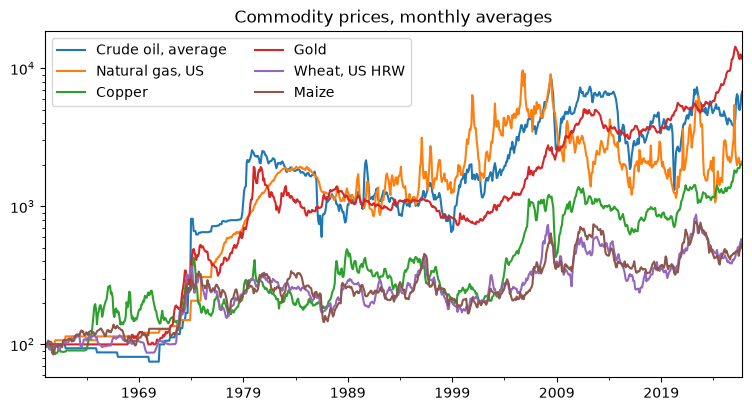

In [122]:
shown = ["Crude oil, average", "Natural gas, US", "Copper", "Gold", "Wheat, US HRW", "Maize"]
rebased = 100 * commodity_prices[shown] / commodity_prices[shown].iloc[0]

ax = rebased.plot(logy=True, title="Commodity prices, monthly averages")
ax.set_xlabel("")
ax.legend(loc="upper left", ncol=2)
plt.show()

### 2.4 Commodity changes and the common sample

Prices are not usable as features, so we work with monthly log price changes, in percent to match the unit of the industry returns. The two panels are then aligned on a common monthly index: the industry returns run from July 1926 to September 2026 and the commodity prices from January 1960 to October 2026, so the common sample is February 1960 to September 2026 (the first month is lost to the difference and October 2026 has no industry return yet).

One choice has to be made about the evaluation period. Oil prices were administered until 1973 and the gold price was fixed until 1968, so their monthly changes are zero for most of the 1960s. We keep the data from 1960, since the first rolling training windows need them, but the results will be reported from January 1973 onwards, when all series actually move.

In [123]:
# Monthly log price changes in percent, same unit as the industry returns
commodity_changes = 100 * np.log(commodity_prices).diff()
commodity_changes = commodity_changes.dropna(how="all")  # the first month has no change

# Common sample: the months where both panels are available
common_months = industry_returns.index.intersection(commodity_changes.index)
industry_returns = industry_returns.loc[common_months]
commodity_changes = commodity_changes.loc[common_months]

EVALUATION_START = "1973-01"  # results are reported from this month onwards (see above)

print(f"Common sample: {common_months[0]:%Y-%m} to {common_months[-1]:%Y-%m}, {len(common_months)} months")
print(f"Industry returns: {industry_returns.shape}, commodity changes: {commodity_changes.shape}")
commodity_changes.tail(3).round(2)

Common sample: 1960-02 to 2026-09, 800 months
Industry returns: (800, 49), commodity changes: (800, 24)


,"Crude oil, average","Crude oil, Brent","Natural gas, US","Coal, Australian",Copper,Aluminum,Nickel,Zinc,Lead,Tin,"Iron ore, cfr spot",Gold,Silver,Platinum,"Wheat, US HRW",Maize,Soybeans,"Rice, Thai 5%","Sugar, world","Cotton, A Index","Coffee, Arabica",Cocoa,Beef,Chicken
month,,,,,,,,,,,,,,,,,,,,,,,,
2026-07-01,-2.35,-2.37,-8.61,-4.88,-0.07,-8.43,-5.47,1.68,-5.49,-0.12,-2.61,-3.73,-12.61,-6.21,8.06,7.95,2.97,-5.62,6.06,3.11,15.27,24.29,-2.03,-2.29
2026-08-01,5.60,8.61,-4.24,2.47,5.62,2.81,0.60,7.39,0.70,4.46,-1.95,7.97,10.64,9.30,6.25,4.85,0.83,0.85,11.12,7.37,0.76,5.88,-0.41,-2.34
2026-09-01,19.23,25.07,6.30,8.44,1.03,0.98,-2.58,3.70,0.97,-3.07,1.44,-2.11,-1.23,0.22,5.02,6.73,8.35,2.31,7.60,-0.48,-9.33,-0.51,-5.94,6.86


### 2.5 Descriptive statistics

Monthly commodity changes since 1973: annualised average and volatility, one-month autocorrelation, and the share of months without any price change.

- Volatility ranges from 13% a year (chicken) to 45% (natural gas), so the features will be standardised before entering the models.
- Monthly changes are positively autocorrelated, about 0.25 on average. This is the mechanical effect of monthly averaging (Working, 1960), not a sign of economic persistence; we will check the results with end-of-month prices later.
- Before 1973 most energy and metal prices did not move (95% of months without change for crude oil), which justifies starting the evaluation in 1973. Iron ore and Australian coal still have stale prices afterwards (57% and 39% of months without change), so they are kept for the robustness checks only.

In [ ]:
# Descriptive statistics of the monthly commodity changes since 1973
since_1973 = commodity_changes.loc[EVALUATION_START:]

commodity_stats = pd.DataFrame({
    "group": commodity_group,
    "mean change (% per year)": 12 * since_1973.mean(),
    "volatility (% per year)": np.sqrt(12) * since_1973.std(),
    "autocorrelation (lag 1 month)": since_1973.apply(lambda s: s.autocorr(1)),
    "months without price change, before 1973 (%)": 100 * (commodity_changes.loc[:"1972"] == 0).mean(),
    "months without price change, since 1973 (%)": 100 * (since_1973 == 0).mean(),
})
commodity_stats.round(2)

,group,average change (% per year),volatility (% per year),autocorrelation (lag 1 month),"months without price change, before 1973 (%)","months without price change, since 1973 (%)"
"Crude oil, average",energy,7.42,34.39,0.22,94.84,9.77
"Crude oil, Brent",energy,7.66,35.11,0.21,94.84,8.84
"Natural gas, US",energy,5.10,45.40,0.03,95.48,9.15
"Coal, Australian",energy,5.08,24.08,0.22,21.29,38.60
Copper,industrial metals,4.93,21.86,0.37,13.55,0.47
Aluminum,industrial metals,3.36,18.24,0.20,84.52,2.02
Nickel,industrial metals,3.10,26.56,0.32,83.23,9.77
Zinc,industrial metals,4.41,22.78,0.29,8.39,0.47
Lead,industrial metals,3.36,23.40,0.21,3.87,1.40
Tin,industrial metals,4.96,20.02,0.32,3.87,0.47


### 2.6 Which industries move with which commodities?

Before testing predictability, we check that the story holds in the same month: do commodity producers rise and users fall when a commodity price goes up? Since the strategies will be long-short across industries, we use industry returns relative to the average industry, which removes the market component, and correlate them with the commodity changes since 1973. With 645 months, a correlation beyond ±0.08 is about two standard errors from zero.

The producer side is clear: Oil (+0.23 with crude oil), Coal (+0.21 with coal), Mines and Steel (+0.26 and +0.25 with copper), and the Gold industry (+0.37 with the gold price). The user side is not where we expected it: Autos and Chems are uncorrelated with oil, while the industries that fall when oil rises are consumer-facing (Meals −0.21, Rtail −0.17, Hshld −0.17) and Trans (−0.11). Agricultural commodities barely matter, except for Agric (+0.14 with soybeans).

In [ ]:
# Correlation of industry returns with commodity changes in the same month, since 1973.
# Industry returns are taken relative to the average industry (the strategies will be long-short).
relative_returns = industry_returns.sub(industry_returns.mean(axis=1), axis=0).loc[EVALUATION_START:]

# One column per commodity ("Gold" is both an industry and a commodity, so we avoid a concat)
correlations = pd.DataFrame({name: relative_returns.corrwith(since_1973[name]) for name in since_1973.columns})

# Industries sorted by their correlation with crude oil
correlations = correlations.sort_values("Crude oil, average", ascending=False)

fig, ax = plt.subplots(figsize=(11, 13))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(len(correlations.columns)), correlations.columns, rotation=90)
ax.set_yticks(range(len(correlations.index)), correlations.index)
fig.colorbar(image, ax=ax, shrink=0.5, label="correlation")
ax.set_title("Same-month correlation of relative industry returns with commodity changes, 1973-2026")
plt.show()

In [ ]:
# Average correlation by commodity group, and the industries at both ends
group_correlations = pd.DataFrame({group: correlations[names].mean(axis=1) for group, names in COMMODITY_GROUPS.items()})

ends = {}
for group in group_correlations.columns:
    ranked = group_correlations[group].sort_values(ascending=False)
    ends[group] = {"most positive": ", ".join(ranked.index[:5]), "most negative": ", ".join(ranked.index[-5:])}
pd.DataFrame(ends).T

*Next step:* Section 3, the predictive test: the baselines (industry momentum, Ridge on past industry returns) and the same pipeline with lagged commodity changes added.